In [27]:
import pandas as pd
import numpy as np

In [28]:
data_healthy_one = pd.read_csv(r"..\data\raw\healthy\span1.CSV")
data_healthy_two = pd.read_csv(r"..\data\raw\healthy\span2.CSV")
data_healthy_three = pd.read_csv(r"..\data\raw\healthy\span3.CSV")
data_defective_one = pd.read_csv(r"..\data\raw\defective\span1.CSV")
data_defective_two = pd.read_csv(r"..\data\raw\defective\span2.CSV")
data_defective_three = pd.read_csv(r"..\data\raw\defective\span3.CSV")

In [29]:
# Step 1: label every row by the folder its file came from
data_healthy_one["condition"] = "healthy"
data_healthy_two["condition"] = "healthy"
data_healthy_three["condition"] = "healthy"
data_defective_one["condition"] = "defective"
data_defective_two["condition"] = "defective"
data_defective_three["condition"] = "defective"

# ...and by the span file it came from (span1, span2 or span3).
# For tracking/grouping only. CLAUDE.md rule: never use this as a model feature.
data_healthy_one["span"] = "span1"
data_healthy_two["span"] = "span2"
data_healthy_three["span"] = "span3"
data_defective_one["span"] = "span1"
data_defective_two["span"] = "span2"
data_defective_three["span"] = "span3"

In [30]:
# Step 2: merge all six into one master DataFrame.
# Order matters for the numbering in step 3: all healthy files first, then all defective.
# ignore_index=True gives the merged rows fresh row numbers 0, 1, 2, ...
master = pd.concat(
    [
        data_healthy_one, data_healthy_two, data_healthy_three,
        data_defective_one, data_defective_two, data_defective_three,
    ],
    ignore_index=True,
)

In [31]:
# Step 3: label each row with its recording (RH1, RH2, ... then RD1, RD2, ...)

# 3a. Remove the repeated header rows. pandas used each file's FIRST header row as
#     column names, but every later header row was read in as a normal row with the
#     text "Time(ms)" in the Time(ms) column.
master = master[master["Time(ms)"] != "Time(ms)"].reset_index(drop=True)

# 3b. Those header rows made pandas store the numbers as text. Convert back to numbers.
numeric_cols = ["Time(ms)", "Ax(g)", "Ay(g)", "Az(g)", "Accel_Magnitude(g)"]
master[numeric_cols] = master[numeric_cols].astype(float)

# 3c. Find where each new recording starts.
#     Every recording's time starts again near 0, so a new recording begins wherever the
#     time is smaller than in the row above. This catches both the header rows we just
#     removed AND the jump from one file to the next (where there was no header row left,
#     because pandas used it for the column names).
#     We also start a new recording where the condition changes (healthy -> defective).
time_went_down = master["Time(ms)"] < master["Time(ms)"].shift()
condition_changed = master["condition"] != master["condition"].shift()
new_recording = time_went_down | condition_changed

# 3d. Count recording starts separately for healthy and defective, so healthy runs
#     1..34 and defective starts again at 1.
recording_number = new_recording.groupby(master["condition"]).cumsum()

# 3e. Add the prefix: RH for healthy, RD for defective.
prefix = master["condition"].map({"healthy": "RH", "defective": "RD"})
master["recording"] = prefix + recording_number.astype(str)

master

,Time(ms),Ax(g),Ay(g),Az(g),Accel_Magnitude(g),condition,span,recording
0,1.0,-0.0527,1.0889,1.0095,1.4858,healthy,span1,RH1
1,71.0,-0.0159,1.1675,1.0288,1.5562,healthy,span1,RH1
2,140.0,-0.0527,1.1567,0.9524,1.4993,healthy,span1,RH1
3,210.0,-0.0232,1.1274,0.9692,1.4870,healthy,span1,RH1
4,281.0,-0.0105,1.1865,0.9907,1.5458,healthy,span1,RH1
...,...,...,...,...,...,...,...,...
8892,11452.0,-0.1790,1.1504,1.0085,1.5403,defective,span3,RD18
8893,11522.0,0.2717,1.2236,1.0664,1.6457,defective,span3,RD18
8894,11591.0,0.2324,0.9209,1.0264,1.3984,defective,span3,RD18
8895,11661.0,-0.0996,1.0791,1.0249,1.4916,defective,span3,RD18


In [32]:
# Quick check. Expected: 8897 rows, 34 healthy recordings, 18 defective recordings,
# and exactly one RH1 and one RD1.
print("Rows:", len(master))
print("Recordings per condition:")
print(master.groupby("condition")["recording"].nunique())
print("First and last recording names:", master["recording"].unique()[[0, 33, 34, 51]])

# Rows in each recording, in the order they appear
master.groupby("recording", sort=False).size()

Rows: 8897
Recordings per condition:
condition
defective    18
healthy      34
Name: recording, dtype: int64
First and last recording names: <StringArray>
['RH1', 'RH34', 'RD1', 'RD18']
Length: 4, dtype: str


recording
RH1     118
RH2     141
RH3     127
RH4     160
RH5     136
RH6     145
RH7     128
RH8     160
RH9     117
RH10    182
RH11    142
RH12    200
RH13    146
RH14    218
RH15    167
RH16    276
RH17    154
RH18    258
RH19    143
RH20    231
RH21    134
RH22    195
RH23    179
RH24    199
RH25    135
RH26    263
RH27    163
RH28    209
RH29    131
RH30    326
RH31    124
RH32    250
RH33    132
RH34    215
RD1     156
RD2     181
RD3     146
RD4     134
RD5     153
RD6     136
RD7     175
RD8     141
RD9     136
RD10    181
RD11    182
RD12    169
RD13    175
RD14    136
RD15    199
RD16    211
RD17    113
RD18    169
dtype: int64

In [33]:
master

,Time(ms),Ax(g),Ay(g),Az(g),Accel_Magnitude(g),condition,span,recording
0,1.0,-0.0527,1.0889,1.0095,1.4858,healthy,span1,RH1
1,71.0,-0.0159,1.1675,1.0288,1.5562,healthy,span1,RH1
2,140.0,-0.0527,1.1567,0.9524,1.4993,healthy,span1,RH1
3,210.0,-0.0232,1.1274,0.9692,1.4870,healthy,span1,RH1
4,281.0,-0.0105,1.1865,0.9907,1.5458,healthy,span1,RH1
...,...,...,...,...,...,...,...,...
8892,11452.0,-0.1790,1.1504,1.0085,1.5403,defective,span3,RD18
8893,11522.0,0.2717,1.2236,1.0664,1.6457,defective,span3,RD18
8894,11591.0,0.2324,0.9209,1.0264,1.3984,defective,span3,RD18
8895,11661.0,-0.0996,1.0791,1.0249,1.4916,defective,span3,RD18


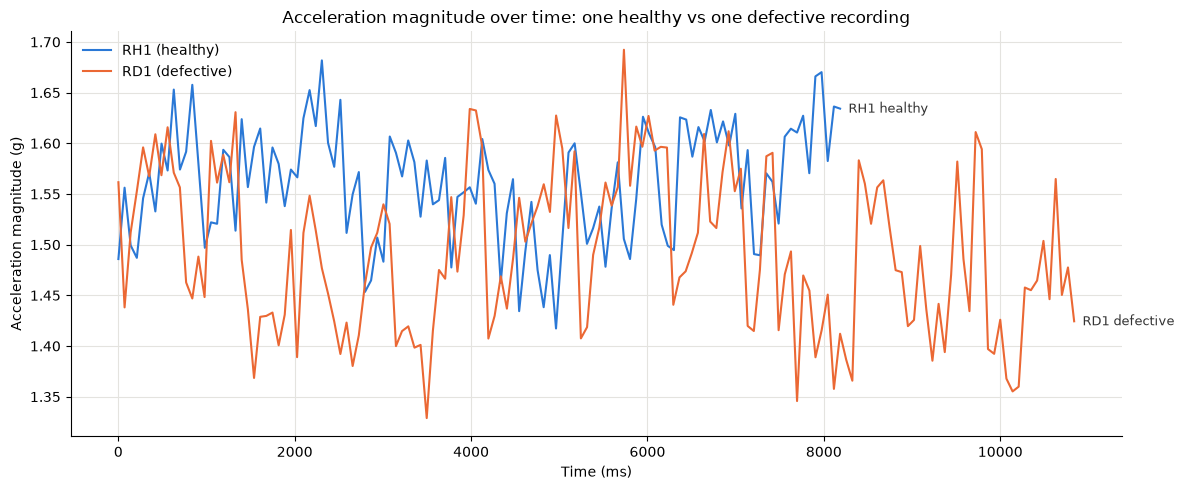

In [34]:
import matplotlib.pyplot as plt

# Pick out the rows for one healthy and one defective recording
rh1 = master[master["recording"] == "RH1"]
rd1 = master[master["recording"] == "RD1"]

HEALTHY_COLOR = "#2a78d6"    # blue
DEFECTIVE_COLOR = "#eb6834"  # orange

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(rh1["Time(ms)"], rh1["Accel_Magnitude(g)"],
        color=HEALTHY_COLOR, linewidth=1.5, label="RH1 (healthy)")
ax.plot(rd1["Time(ms)"], rd1["Accel_Magnitude(g)"],
        color=DEFECTIVE_COLOR, linewidth=1.5, label="RD1 (defective)")

# Label each line at its right-hand end, so you don't have to look at the legend
for df, name in [(rh1, "RH1 healthy"), (rd1, "RD1 defective")]:
    last = df.iloc[-1]
    ax.annotate(name, xy=(last["Time(ms)"], last["Accel_Magnitude(g)"]),
                xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#333333")

ax.set_title("Acceleration magnitude over time: one healthy vs one defective recording")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Acceleration magnitude (g)")
ax.legend(frameon=False, loc="upper left")

# Light, unobtrusive background grid; remove the top and right box lines
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Line plot of the first healthy recording and the first defective recording.

This is to check if there are major differences between healthy and defective shaking.

The defective recording sits slightly lower on the chart, and swings around much more wildly than the healthy recording.

However, this shouldn't be taken at face value, it's relatively small data - only one recording for both healthy and defective.

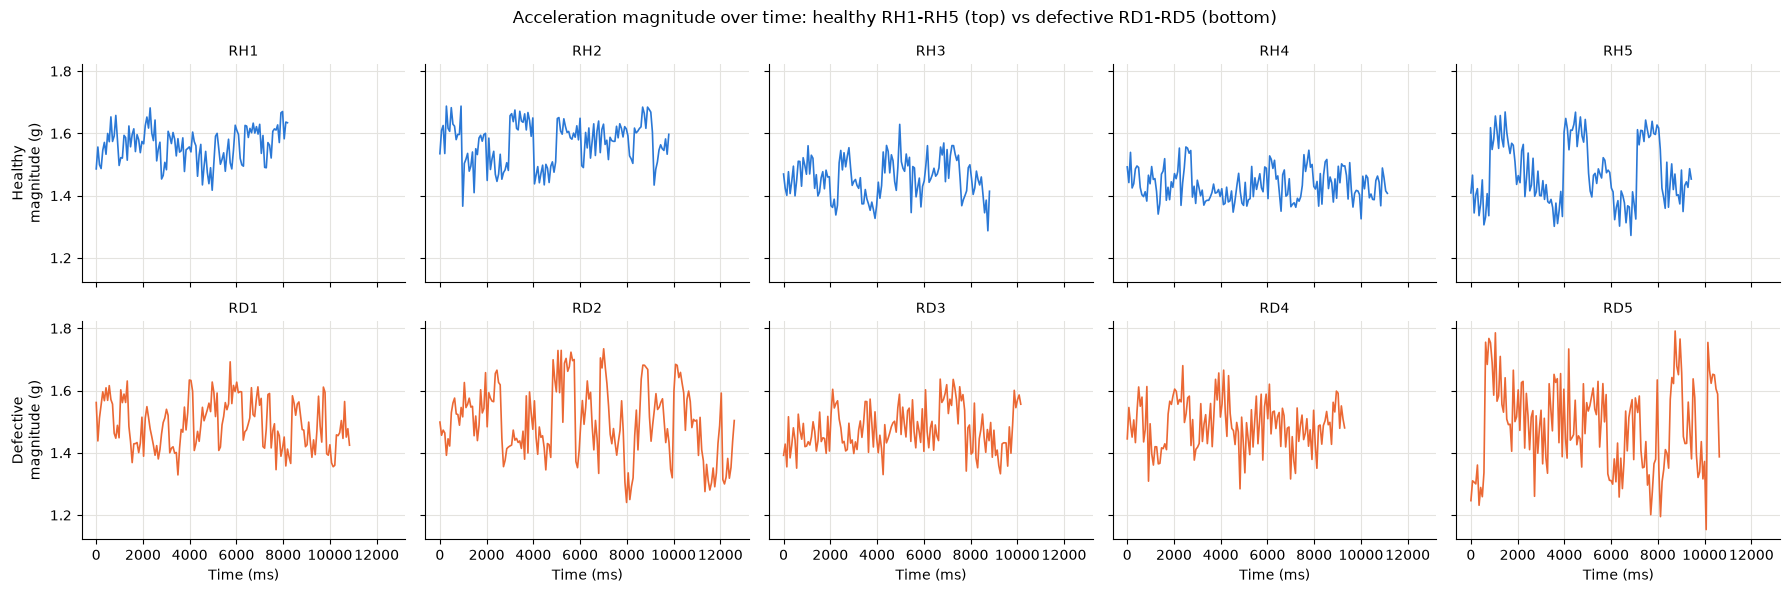

In [35]:
# Grid of small charts: healthy RH1-RH5 on the top row, defective RD1-RD5 on the bottom row.
# sharex/sharey=True puts every small chart on the SAME scales, so they can be compared fairly.

healthy_recs = ["RH1", "RH2", "RH3", "RH4", "RH5"]
defective_recs = ["RD1", "RD2", "RD3", "RD4", "RD5"]

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(18, 6), sharex=True, sharey=True)

for row, (recs, color, row_name) in enumerate([
    (healthy_recs, HEALTHY_COLOR, "Healthy"),
    (defective_recs, DEFECTIVE_COLOR, "Defective"),
]):
    for col, rec in enumerate(recs):
        ax = axes[row, col]
        data = master[master["recording"] == rec]
        ax.plot(data["Time(ms)"], data["Accel_Magnitude(g)"], color=color, linewidth=1.2)

        ax.set_title(rec, fontsize=10)
        ax.grid(color="#e4e3df", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    # Name each row on its left-most chart
    axes[row, 0].set_ylabel(f"{row_name}\nmagnitude (g)")

# Time label only on the bottom row
for ax in axes[1]:
    ax.set_xlabel("Time (ms)")

fig.suptitle("Acceleration magnitude over time: healthy RH1-RH5 (top) vs defective RD1-RD5 (bottom)")
plt.tight_layout()
plt.show()

This image shows five healthy recordings from span 1 (1.0m) and five defective recordings from span 1 as well (1.0m). 

What was observed in the RH1 and RD1 plot is also observed in these line plots here - the defective readings seem to show more volatility (wild swings) in recordings.

In [36]:
# Boil each recording down to ONE number: the standard deviation of its acceleration magnitude
# (how much the signal swings around its own average). Result: one row per recording, 52 rows.
recording_std = (
    master.groupby(["recording", "condition", "span"], sort=False)["Accel_Magnitude(g)"]
    .std()
    .reset_index(name="std_magnitude")
)

print("Recordings per condition:")
print(recording_std["condition"].value_counts())   # expected: healthy 34, defective 18
print()
print(recording_std.groupby("condition", sort=False)["std_magnitude"].describe())

recording_std

Recordings per condition:
condition
healthy      34
defective    18
Name: count, dtype: int64

           count      mean       std       min       25%       50%       75%  \
condition                                                                      
healthy     34.0  0.091045  0.029709  0.051006  0.062877  0.091144  0.108529   
defective   18.0  0.106214  0.031504  0.056921  0.078960  0.105009  0.117627   

                max  
condition            
healthy    0.150233  
defective  0.177333  


,recording,condition,span,std_magnitude
0,RH1,healthy,span1,0.055797
1,RH2,healthy,span1,0.069762
2,RH3,healthy,span1,0.062844
3,RH4,healthy,span1,0.051006
4,RH5,healthy,span1,0.103202
5,RH6,healthy,span1,0.150233
6,RH7,healthy,span1,0.138578
7,RH8,healthy,span1,0.148507
8,RH9,healthy,span1,0.102065
9,RH10,healthy,span1,0.123148


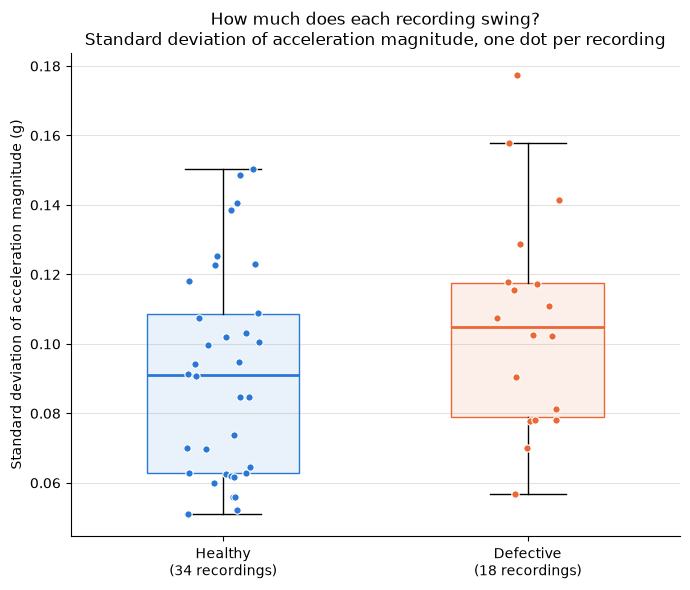

In [37]:
# Box plot of the per-recording standard deviation: healthy vs defective, side by side.
# Each dot on top is one recording, so you can see all 52 values, not just the box summary.

healthy_std = recording_std.loc[recording_std["condition"] == "healthy", "std_magnitude"]
defective_std = recording_std.loc[recording_std["condition"] == "defective", "std_magnitude"]

fig, ax = plt.subplots(figsize=(7, 6))

boxes = ax.boxplot(
    [healthy_std, defective_std],
    tick_labels=[f"Healthy\n({len(healthy_std)} recordings)",
                 f"Defective\n({len(defective_std)} recordings)"],
    widths=0.5,
    patch_artist=True,     # lets us colour the boxes
    showfliers=False,      # outliers are already shown as dots below, don't draw them twice
)

for box, median, color in zip(boxes["boxes"], boxes["medians"], [HEALTHY_COLOR, DEFECTIVE_COLOR]):
    box.set_facecolor(color + "1A")  # same colour, ~10% opacity (a light wash)
    box.set_edgecolor(color)
    median.set_color(color)
    median.set_linewidth(2)

# One dot per recording. Spread the dots sideways a little (jitter) so they don't sit on top
# of each other. The sideways position means nothing; only the height matters.
rng = np.random.default_rng(0)   # fixed seed, so the dots land in the same place every run
for position, values, color in [(1, healthy_std, HEALTHY_COLOR), (2, defective_std, DEFECTIVE_COLOR)]:
    x = position + rng.uniform(-0.12, 0.12, size=len(values))
    ax.scatter(x, values, color=color, s=28, edgecolor="white", linewidth=0.8, zorder=3)

ax.set_title("How much does each recording swing?\nStandard deviation of acceleration magnitude, one dot per recording")
ax.set_ylabel("Standard deviation of acceleration magnitude (g)")
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

This box plot shows that there is a slight difference between healthy and defective pipe vibrations. 

The median line in defective pipes sits higher than that in healthy pipelines. This means the defective pipes tend to shake a bit more.

There is also a major overlap. Almost the entire defective box sits inside the healthy box. This means that standard deviation alone wouldn't be enough of a differentiator. More features would be used. 

condition  flow
defective  slow    18
healthy    fast    17
           slow    17
dtype: int64


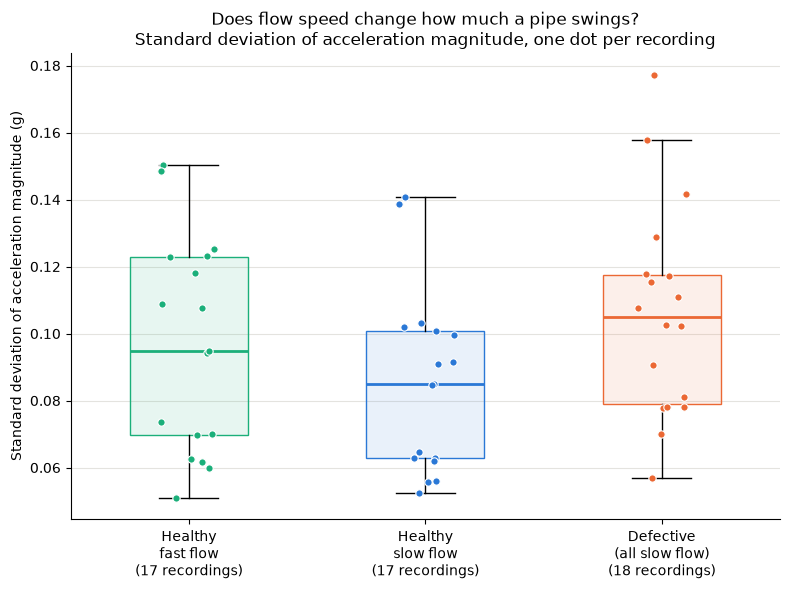

count   mean    std    min    25%    50%    75%    max
condition flow                                                        
healthy   slow   17.0  0.085  0.027  0.052  0.063  0.085  0.101  0.141
          fast   17.0  0.097  0.032  0.051  0.070  0.095  0.123  0.150
defective slow   18.0  0.106  0.032  0.057  0.079  0.105  0.118  0.177

In [38]:
# --- 1. Work out each recording's flow speed (see "Flow Speed Explanation.md") ---
# Rule: inside each HEALTHY file, recordings go slow, fast, slow, fast, ...
#   -> 1st, 3rd, 5th ... recording in the file = slow; 2nd, 4th, 6th ... = fast.
# All DEFECTIVE recordings were slow.
#
# Our names run on across files (RH13 is the 1st recording of span2), so first find each
# recording's position INSIDE its own file: count 1, 2, 3, ... within each condition + span.
recording_std["number_in_file"] = recording_std.groupby(["condition", "span"]).cumcount() + 1

recording_std["flow"] = "slow"
is_fast = (recording_std["condition"] == "healthy") & (recording_std["number_in_file"] % 2 == 0)
recording_std.loc[is_fast, "flow"] = "fast"

# Expected: 17 healthy fast, 17 healthy slow, 18 defective slow
print(recording_std.groupby(["condition", "flow"]).size())

# --- 2. Box plot with three boxes ---
HEALTHY_FAST_COLOR = "#1baf7a"   # green
HEALTHY_SLOW_COLOR = "#2a78d6"   # blue (same blue as healthy before)

groups = [
    ("Healthy\nfast flow", (recording_std["condition"] == "healthy") & (recording_std["flow"] == "fast"), HEALTHY_FAST_COLOR),
    ("Healthy\nslow flow", (recording_std["condition"] == "healthy") & (recording_std["flow"] == "slow"), HEALTHY_SLOW_COLOR),
    ("Defective\n(all slow flow)", recording_std["condition"] == "defective", DEFECTIVE_COLOR),
]
values = [recording_std.loc[mask, "std_magnitude"] for _, mask, _ in groups]
colors = [color for _, _, color in groups]
labels = [f"{name}\n({len(v)} recordings)" for (name, _, _), v in zip(groups, values)]

fig, ax = plt.subplots(figsize=(8, 6))

boxes = ax.boxplot(values, tick_labels=labels, widths=0.5, patch_artist=True, showfliers=False)

for box, median, color in zip(boxes["boxes"], boxes["medians"], colors):
    box.set_facecolor(color + "1A")  # light wash of the same colour
    box.set_edgecolor(color)
    median.set_color(color)
    median.set_linewidth(2)

# One dot per recording (sideways spread is only to stop dots overlapping)
rng = np.random.default_rng(0)
for position, (v, color) in enumerate(zip(values, colors), start=1):
    x = position + rng.uniform(-0.12, 0.12, size=len(v))
    ax.scatter(x, v, color=color, s=28, edgecolor="white", linewidth=0.8, zorder=3)

ax.set_title("Does flow speed change how much a pipe swings?\nStandard deviation of acceleration magnitude, one dot per recording")
ax.set_ylabel("Standard deviation of acceleration magnitude (g)")
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# Numbers behind the boxes
recording_std.groupby(["condition", "flow"], sort=False)["std_magnitude"].describe().round(3)

The box plot above has the healthy recordings split into fast flow and slow flow. The defective recordings were not split because the entirety of tests on defective pipes were done with slow flow.

The method used to arrive at which recordings were fast and which were slow are specified in the md file titled "Flow SPeed Explanation.md". Feel free to read through its contents.

The box plot shows that there is a vibration difference in fast flow against slow flow. The median line for fast flow sits higher than that of slow flow. This shows that fast flow tends to vibrate the same pipe more than slow flow. Noted.

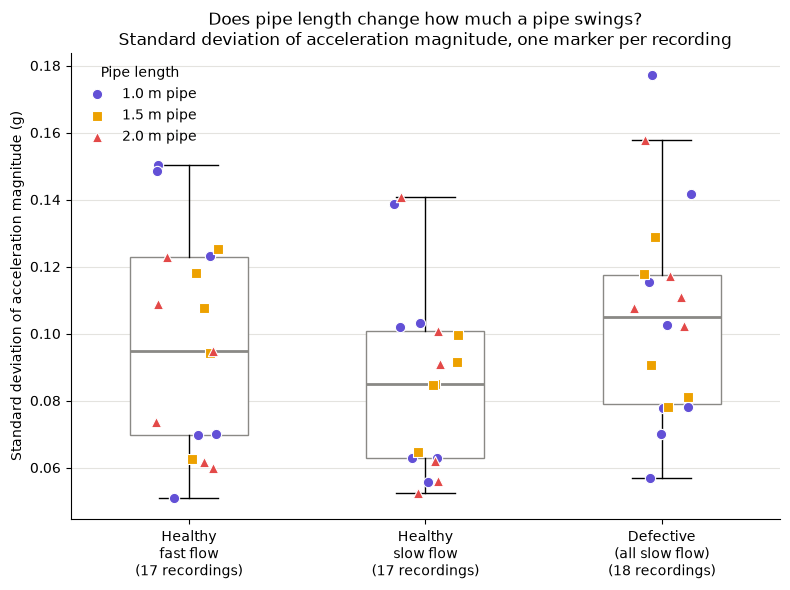

pipe_length_m     1.0    1.5    2.0
condition flow                     
healthy   slow  0.083  0.085  0.076
          fast  0.097  0.108  0.084
defective slow  0.090  0.091  0.111

In [39]:
#color code dots in box plot by span file. this tells by length.

# Same three boxes as above (healthy fast, healthy slow, defective), but now every dot is
# coloured by the pipe length it was recorded on. Pipe lengths are from "Flow Speed Explanation.md":
# span1 = 1.0 m, span2 = 1.5 m, span3 = 2.0 m.
#
# Each length gets its own colour AND its own marker shape, so they're easy to tell apart.
# The boxes are plain grey here, because colour now means LENGTH, not group.

recording_std["pipe_length_m"] = recording_std["span"].map({"span1": 1.0, "span2": 1.5, "span3": 2.0})

LENGTH_STYLE = {
    1.0: {"color": "#6250d6", "marker": "o"},  # violet circle
    1.5: {"color": "#eda100", "marker": "s"},  # yellow square
    2.0: {"color": "#e34948", "marker": "^"},  # red triangle
}
BOX_GREY = "#8a8985"

fig, ax = plt.subplots(figsize=(8, 6))

# `values` and `labels` come from the flow-speed cell above (same three groups, same order)
boxes = ax.boxplot(values, tick_labels=labels, widths=0.5, patch_artist=True, showfliers=False)
for box, median in zip(boxes["boxes"], boxes["medians"]):
    box.set_facecolor("white")
    box.set_edgecolor(BOX_GREY)
    median.set_color(BOX_GREY)
    median.set_linewidth(2)

# One marker per recording, styled by pipe length
rng = np.random.default_rng(0)
for position, (_, mask, _) in enumerate(groups, start=1):
    group = recording_std[mask].copy()
    group["x"] = position + rng.uniform(-0.14, 0.14, size=len(group))  # sideways spread only
    for length, style in LENGTH_STYLE.items():
        part = group[group["pipe_length_m"] == length]
        ax.scatter(part["x"], part["std_magnitude"], color=style["color"], marker=style["marker"],
                   s=55, edgecolor="white", linewidth=0.8, zorder=3,
                   label=f"{length} m pipe" if position == 1 else None)  # legend entry once

ax.legend(title="Pipe length", frameon=False, loc="upper left")

ax.set_title("Does pipe length change how much a pipe swings?\nStandard deviation of acceleration magnitude, one marker per recording")
ax.set_ylabel("Standard deviation of acceleration magnitude (g)")
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# Numbers behind the markers: median standard deviation for each group and pipe length
recording_std.pivot_table(index=["condition", "flow"], columns="pipe_length_m",
                          values="std_magnitude", aggfunc="median", sort=False).round(3)

The chart generated above is the same box plot as before. This one howver identifies each point by pipe length, as shown in the key in the chart.

The chart shows that pipe length has no corellation with vibration magnitude. Fears have been allayed.